# CSE485-CSE488: Deep Learning — Assignment 1
## MicroGrad: Scalar Automatic Differentiation Engine & Neural Network API
**Student Name:** Ahmed Mostafa  
**Student ID:** 23p0375  
**University:** Ain Shams University  
**Course:** Deep Learning (Fall 2026)  

---

### Notebook Overview
This notebook provides a complete, educational, and reproducible walkthrough of **MicroGrad**, a scalar-level automatic differentiation engine implemented from scratch in pure Python.

Key topics covered:
1. **Automatic Differentiation Fundamentals**: Forward vs. Reverse mode, adjoints, and computational graphs.
2. **Computational Graph Construction**: Scalar values (`Value`), dynamic Directed Acyclic Graphs (DAGs), and operator overloading.
3. **Graph Visualization**: Graph inspection with node values, operations, and adjoint gradients.
4. **Analytic Derivatives vs. Engine Backprop**: Verification of manual calculus derivations against automated reverse-mode autodiff.
5. **The Diamond Graph & Gradient Accumulation**: Why gradients must accumulate using `+=` rather than overwrite with `=`.
6. **Finite-Difference Numerical Gradient Checking**: Validating local and global derivatives via symmetric difference quotients.
7. **Neural Network Architecture**: Building `Neuron`, `Layer`, and `MLP` from fundamental scalar operations.
8. **End-to-End Model Training**: Optimizing an MLP on a non-linear dataset using pure gradient descent, with loss visualization and prediction analysis.


In [1]:
import math
import random
import matplotlib.pyplot as plt

# Ensure reproducible random initializations
random.seed(1337)

# Import engine and neural network classes
from src.engine import Value
from src.nn import Neuron, Layer, MLP

print("MicroGrad engine and neural network modules loaded successfully!")


MicroGrad engine and neural network modules loaded successfully!


## 1. Introduction to Automatic Differentiation (Autodiff)

In scientific computing and deep learning, derivatives of complex composite functions must be evaluated efficiently. There are three primary paradigms:

1. **Numerical Differentiation (Finite Differences):**
   $$f'(x) \approx \frac{f(x + h) - f(x - h)}{2h}$$
   - *Pros:* Simple to implement; treats functions as black boxes.
   - *Cons:* Prone to round-off and truncation errors; computationally expensive for high-dimensional models ($O(N)$ forward passes for $N$ parameters).

2. **Symbolic Differentiation:**
   - Evaluates closed-form mathematical expressions (e.g., SymPy, Mathematica).
   - *Cons:* Suffers from expression swell where formulas grow exponentially in size.

3. **Automatic Differentiation (Autodiff):**
   - Decomposes computer programs into elementary mathematical primitives ($+, -, \times, /, \exp, \tanh$) and applies the chain rule at each step.
   - **Reverse-Mode Autodiff (Backpropagation):** Computes gradients of a scalar objective (e.g., loss $\mathcal{L}$) with respect to *all* parameters in a single backward pass ($O(1)$ complexity relative to forward evaluation).


## 2. Scalar Computational Graphs & Arithmetic

A computational graph is a Directed Acyclic Graph (DAG) where:
- Leaf nodes represent inputs, weights, or constants.
- Internal nodes represent intermediate mathematical operations.
- Edges represent data dependencies.

Let us construct an arithmetic computational graph:
$$c = a + b, \quad d = a \times b$$


In [2]:
a = Value(2.0, label='a')
b = Value(3.0, label='b')

c = a + b
c.label = 'c'
d = a * b
d.label = 'd'

print(f"a = {a}, data = {a.data}")
print(f"b = {b}, data = {b.data}")
print(f"c = a + b -> {c}, data = {c.data}")
print(f"d = a * b -> {d}, data = {d.data}")


a = Value(data=2.0), data = 2.0
b = Value(data=3.0), data = 3.0
c = a + b -> Value(data=5.0), data = 5.0
d = a * b -> Value(data=6.0), data = 6.0


## 3. Computational Graph Visualization

To inspect the structure of dynamic DAGs, we trace the graph backwards from any output node using Depth-First Search (DFS) and display the data and gradients of each node alongside the generating operations.


<string>:85: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


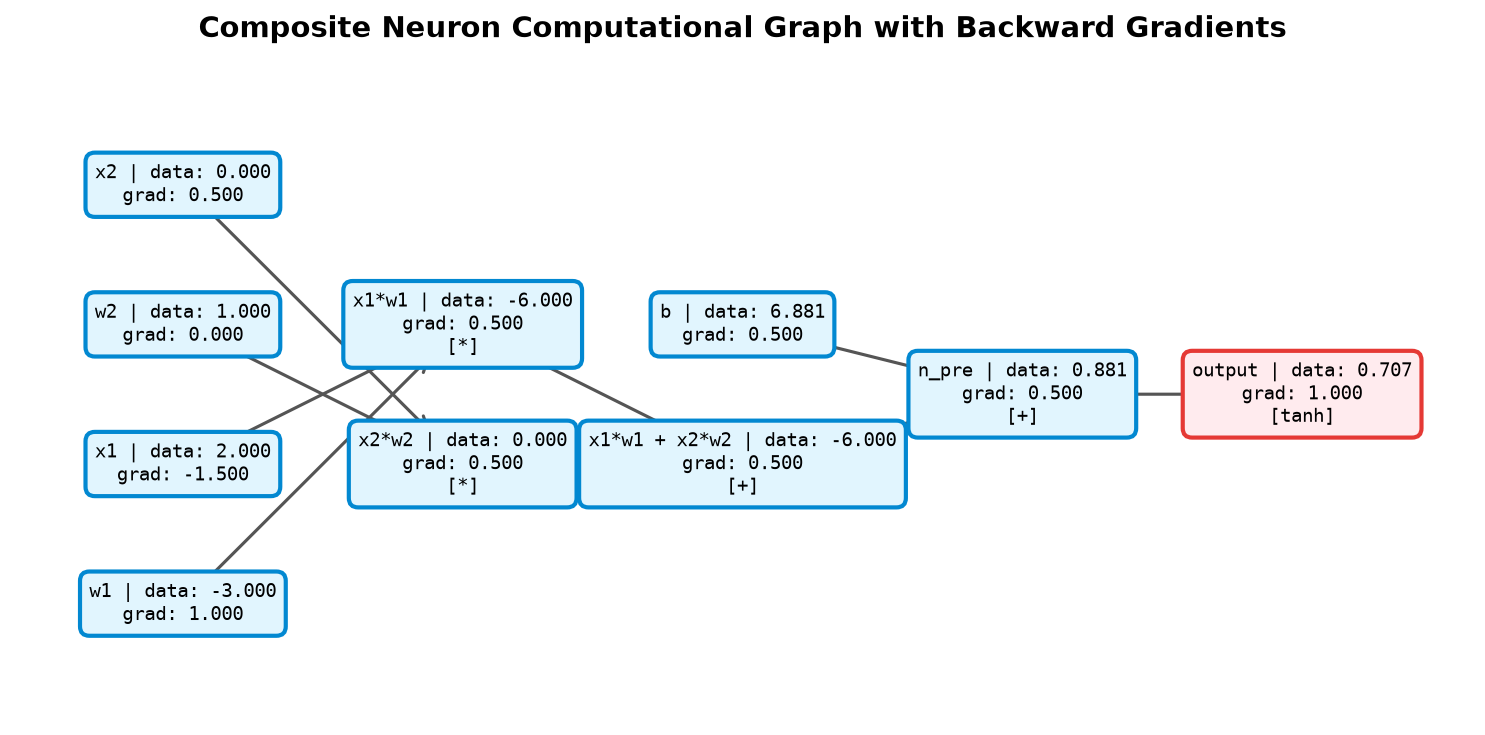

In [3]:
def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_graph_matplotlib(root, title="Computational Graph"):
    nodes, edges = trace(root)
    topo = root._get_topo()
    
    # Assign layer depth for visualization
    depths = {root: 0}
    for n in reversed(topo):
        d = depths[n]
        for p in n._prev:
            depths[p] = max(depths.get(p, 0), d + 1)
            
    max_depth = max(depths.values()) if depths else 0
    layers = {}
    for n, d in depths.items():
        layer_idx = max_depth - d
        layers.setdefault(layer_idx, []).append(n)
        
    pos = {}
    for layer_idx, layer_nodes in layers.items():
        k = len(layer_nodes)
        for i, n in enumerate(layer_nodes):
            pos[n] = (layer_idx * 2.5, (i - (k - 1) / 2.0) * 1.8)
            
    fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
    
    # Draw edges
    for p, c in edges:
        x1, y1 = pos[p]
        x2, y2 = pos[c]
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle="->", color="#555555", lw=1.5,
                                    shrinkA=22, shrinkB=22, mutation_scale=15))
        
    # Draw nodes
    for n in nodes:
        x, y = pos[n]
        label_text = f"{n.label + ' | ' if n.label else ''}data: {n.data:.3f}\ngrad: {n.grad:.3f}"
        if n._op:
            label_text += f"\n[{n._op}]"
        
        box_color = '#e1f5fe' if n != root else '#ffebee'
        edge_color = '#0288d1' if n != root else '#e53935'
        
        ax.text(x, y, label_text, ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.5', facecolor=box_color,
                          edgecolor=edge_color, lw=2),
                fontsize=9, family='monospace')
                
    ax.axis('off')
    all_x = [p[0] for p in pos.values()]
    all_y = [p[1] for p in pos.values()]
    ax.set_xlim(min(all_x) - 1.5, max(all_x) + 1.5)
    ax.set_ylim(min(all_y) - 1.5, max(all_y) + 1.5)
    plt.tight_layout()
    return fig

# Demonstrate graph drawing on a composite expression
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')

x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
x1w1_x2w2 = x1w1 + x2w2; x1w1_x2w2.label = 'x1*w1 + x2*w2'
n_pre = x1w1_x2w2 + b; n_pre.label = 'n_pre'
out_node = n_pre.tanh(); out_node.label = 'output'

out_node.backward()
fig = draw_graph_matplotlib(out_node, title="Composite Neuron Computational Graph with Backward Gradients")
fig.savefig('report/figures/computation_graph.png', bbox_inches='tight')
plt.show()


## 4. Manual Derivative Calculation vs. Backpropagation

Consider the composite computational graph:
$$d = a \times b, \quad e = a + b, \quad f = d \times e$$
Expanding $f$ in terms of independent inputs $a$ and $b$:
$$f(a, b) = (a \cdot b)(a + b) = a^2 b + a b^2$$

### Analytical Partial Derivatives:
$$\frac{\partial f}{\partial a} = 2ab + b^2$$
$$\frac{\partial f}{\partial b} = a^2 + 2ab$$

For $a = -2.0$ and $b = 3.0$:
$$\frac{\partial f}{\partial a} = 2(-2)(3) + (3)^2 = -12 + 9 = -3.0$$
$$\frac{\partial f}{\partial b} = (-2)^2 + 2(-2)(3) = 4 - 12 = -8.0$$

Let us verify that MicroGrad calculates these exact values through reverse-mode topological backpropagation:


In [4]:
a = Value(-2.0, label='a')
b = Value(3.0, label='b')

d = a * b; d.label = 'd'
e = a + b; e.label = 'e'
f = d * e; f.label = 'f'

# Run backward pass
f.backward()

# Theoretical values
analytical_df_da = 2 * a.data * b.data + b.data**2
analytical_df_db = a.data**2 + 2 * a.data * b.data

print("=== Manual vs Engine Gradient Comparison ===")
print(f"Output f = {f.data:.4f} (Expected: {(-2.0 * 3.0) * (-2.0 + 3.0):.4f})")
print(f"df/da: Engine = {a.grad:.4f} | Analytical = {analytical_df_da:.4f} | Match = {math.isclose(a.grad, analytical_df_da)}")
print(f"df/db: Engine = {b.grad:.4f} | Analytical = {analytical_df_db:.4f} | Match = {math.isclose(b.grad, analytical_df_db)}")


=== Manual vs Engine Gradient Comparison ===
Output f = -6.0000 (Expected: -6.0000)
df/da: Engine = -3.0000 | Analytical = -3.0000 | Match = True
df/db: Engine = -8.0000 | Analytical = -8.0000 | Match = True


## 5. Diamond Graph & Gradient Accumulation

A crucial bug in naive autograd implementations occurs in **diamond graphs**, where a single node branches into multiple paths that later recombine.

Consider:
$$c = a + a = 2a$$
$$d = c \times a = (2a) \times a = 2a^2$$

Using calculus:
$$\frac{\partial d}{\partial a} = \frac{\partial d}{\partial c} \frac{\partial c}{\partial a} + \frac{\partial d}{\partial a}_{\text{direct}} = a \cdot (1 + 1) + c \cdot 1 = 2a + 2a = 4a$$
For $a = 3.0$:
$$\frac{\partial d}{\partial a} = 4(3) = 12.0$$

If gradients were assigned using `=` instead of accumulated with `+=`, the second backward call would overwrite the first, incorrectly yielding $6.0$ instead of $12.0$.


In [5]:
a = Value(3.0, label='a')
c = a + a; c.label = 'c'
d = c * a; d.label = 'd'

d.backward()

expected_d = 2 * (3.0**2)
expected_grad = 4 * 3.0

print(f"d.data = {d.data} (Expected: {expected_d})")
print(f"a.grad = {a.grad} (Expected: {expected_grad})")
assert a.grad == expected_grad, f"Gradient accumulation failed! Expected {expected_grad}, got {a.grad}"
print("Gradient accumulation test passed successfully!")


d.data = 18.0 (Expected: 18.0)
a.grad = 12.0 (Expected: 12.0)
Gradient accumulation test passed successfully!


## 6. Numerical Gradient Checking (Finite Differences)

To guarantee that local derivatives and chain rule composition are bug-free across arbitrary graphs, we implement a **symmetric difference quotient** gradient checker:
$$f'(x) \approx \frac{f(x + h) - f(x - h)}{2h}, \quad h = 10^{-6}$$

We evaluate this on a highly non-linear computational graph combining addition, multiplication, powers, division, $\tanh$, and $\exp$:
$$z = \tanh\left(\frac{x \cdot y + x^2}{y + 1}\right) + \exp(0.5 \cdot x)$$


In [6]:
def test_graph(x_val, y_val):
    x = Value(x_val)
    y = Value(y_val)
    z = ((x * y + (x ** 2)) / (y + 1.0)).tanh() + (x * 0.5).exp()
    return z, x, y

h = 1e-6
x0, y0 = 1.5, 2.5

# Analytical gradients via MicroGrad backward pass
z, x, y = test_graph(x0, y0)
z.backward()
grad_x_analytical = x.grad
grad_y_analytical = y.grad

# Numerical gradient wrt x
z_x_plus, _, _ = test_graph(x0 + h, y0)
z_x_minus, _, _ = test_graph(x0 - h, y0)
grad_x_numerical = (z_x_plus.data - z_x_minus.data) / (2.0 * h)

# Numerical gradient wrt y
z_y_plus, _, _ = test_graph(x0, y0 + h)
z_y_minus, _, _ = test_graph(x0, y0 - h)
grad_y_numerical = (z_y_plus.data - z_y_minus.data) / (2.0 * h)

rel_err_x = abs(grad_x_analytical - grad_x_numerical) / (abs(grad_x_analytical) + abs(grad_x_numerical))
rel_err_y = abs(grad_y_analytical - grad_y_numerical) / (abs(grad_y_analytical) + abs(grad_y_numerical))

print("=== Numerical Gradient Checking Results ===")
print(f"Var x: Analytical = {grad_x_analytical:.8f} | Numerical = {grad_x_numerical:.8f} | Rel Error = {rel_err_x:.2e}")
print(f"Var y: Analytical = {grad_y_analytical:.8f} | Numerical = {grad_y_numerical:.8f} | Rel Error = {rel_err_y:.2e}")

assert rel_err_x < 1e-5 and rel_err_y < 1e-5, "Numerical gradient check failed!"
print("Gradient checking verified with relative error < 1e-5!")


=== Numerical Gradient Checking Results ===
Var x: Analytical = 1.24975863 | Numerical = 1.24975863 | Rel Error = 3.17e-11
Var y: Analytical = -0.00745163 | Numerical = -0.00745163 | Rel Error = 1.16e-08
Gradient checking verified with relative error < 1e-5!


## 7. Building Neural Network Components

MicroGrad implements a PyTorch-inspired API consisting of:
1. `Neuron(nin)`: Computes $\tanh\left(\sum_{i=1}^{n_{\text{in}}} w_i x_i + b\right)$. Contains $n_{\text{in}} + 1$ trainable parameters.
2. `Layer(nin, nout)`: A parallel collection of $n_{\text{out}}$ independent neurons.
3. `MLP(nin, nouts)`: A sequential stack of layers mapping an input vector to the output predictions.


In [7]:
# 1. Test single Neuron
n = Neuron(3)
x_sample = [Value(1.0), Value(-2.0), Value(0.5)]
out_neuron = n(x_sample)
print(f"Neuron: inputs = 3, params = {len(n.parameters())}, output = {out_neuron.data:.4f}")

# 2. Test Layer
l = Layer(nin=3, nout=4)
out_layer = l(x_sample)
print(f"Layer: nin = 3, nout = 4, total params = {len(l.parameters())}, outputs count = {len(out_layer)}")

# 3. Test Multi-Layer Perceptron (MLP)
mlp = MLP(nin=3, nouts=[4, 4, 1])
out_mlp = mlp(x_sample)
print(f"MLP: layers = {len(mlp.layers)}, total params = {len(mlp.parameters())}, final output = {out_mlp.data:.4f}")


Neuron: inputs = 3, params = 4, output = 0.1390
Layer: nin = 3, nout = 4, total params = 16, outputs count = 4
MLP: layers = 3, total params = 41, final output = -0.4938


## 8. Training a Neural Network using Pure MicroGrad

Now, we train an MLP on a synthetic binary classification task.

### Dataset:
Four input vectors in $\mathbb{R}^3$ with corresponding target labels $y \in \{-1.0, 1.0\}$:
- $x^{(1)} = [2.0, 3.0, -1.0] \to y^{(1)} = 1.0$
- $x^{(2)} = [3.0, -1.0, 0.5] \to y^{(2)} = -1.0$
- $x^{(3)} = [0.5, 1.0, 1.0] \to y^{(3)} = -1.0$
- $x^{(4)} = [1.0, 1.0, -1.0] \to y^{(4)} = 1.0$

### Loss Function (Mean Squared Error):
$$\mathcal{L} = \sum_{i=1}^N (\hat{y}_i - y_i)^2$$

### Optimization Loop:
1. **Forward Pass:** Compute predictions $\hat{y}_i = \text{MLP}(x^{(i)})$.
2. **Loss Computation:** Evaluate total scalar loss $\mathcal{L}$.
3. **Zero Gradients:** Clear prior accumulation with `mlp.zero_grad()`.
4. **Backward Pass:** Call `loss.backward()` to populate gradients for all 41 parameters.
5. **Gradient Descent Step:** Update $p.\text{data} \leftarrow p.\text{data} - \eta \cdot p.\text{grad}$.


In [8]:
# Initialize model with 3 inputs, two hidden layers of 4 neurons, and 1 output neuron
random.seed(1337)
model = MLP(3, [4, 4, 1])

xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]
ys = [1.0, -1.0, -1.0, 1.0]

epochs = 100
learning_rate = 0.05
loss_history = []

print(f"Starting training for {epochs} epochs (learning rate = {learning_rate})...")

for epoch in range(epochs):
    # 1. Forward pass
    ypred = [model(x) for x in xs]
    
    # 2. Compute MSE loss
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
    
    # 3. Zero gradients
    model.zero_grad()
    
    # 4. Backward pass
    loss.backward()
    
    # 5. Parameter update (Gradient Descent)
    for p in model.parameters():
        p.data -= learning_rate * p.grad
        
    loss_history.append(loss.data)
    
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:3d} | Loss: {loss.data:.6f}")

print("\nTraining Complete!")
print(f"Initial Loss: {loss_history[0]:.6f}")
print(f"Final Loss:   {loss_history[-1]:.6f}")


Starting training for 100 epochs (learning rate = 0.05)...
Epoch   1 | Loss: 6.005403
Epoch  10 | Loss: 0.846993
Epoch  20 | Loss: 0.059642
Epoch  30 | Loss: 0.027199
Epoch  40 | Loss: 0.017229
Epoch  50 | Loss: 0.012490
Epoch  60 | Loss: 0.009747
Epoch  70 | Loss: 0.007967
Epoch  80 | Loss: 0.006723
Epoch  90 | Loss: 0.005806
Epoch 100 | Loss: 0.005104

Training Complete!
Initial Loss: 6.005403
Final Loss:   0.005104


## 9. Visualizing Loss Convergence & Prediction Accuracy

Let us plot the optimization trajectory across all training epochs and compare the final predictions against the ground truth labels.


=== Final Evaluation ===
Sample 1: Target = +1.0 | Prediction = +0.9593 | Error = 0.0407
Sample 2: Target = -1.0 | Prediction = -0.9915 | Error = 0.0085
Sample 3: Target = -1.0 | Prediction = -0.9601 | Error = 0.0399
Sample 4: Target = +1.0 | Prediction = +0.9585 | Error = 0.0415


<string>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
<string>:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


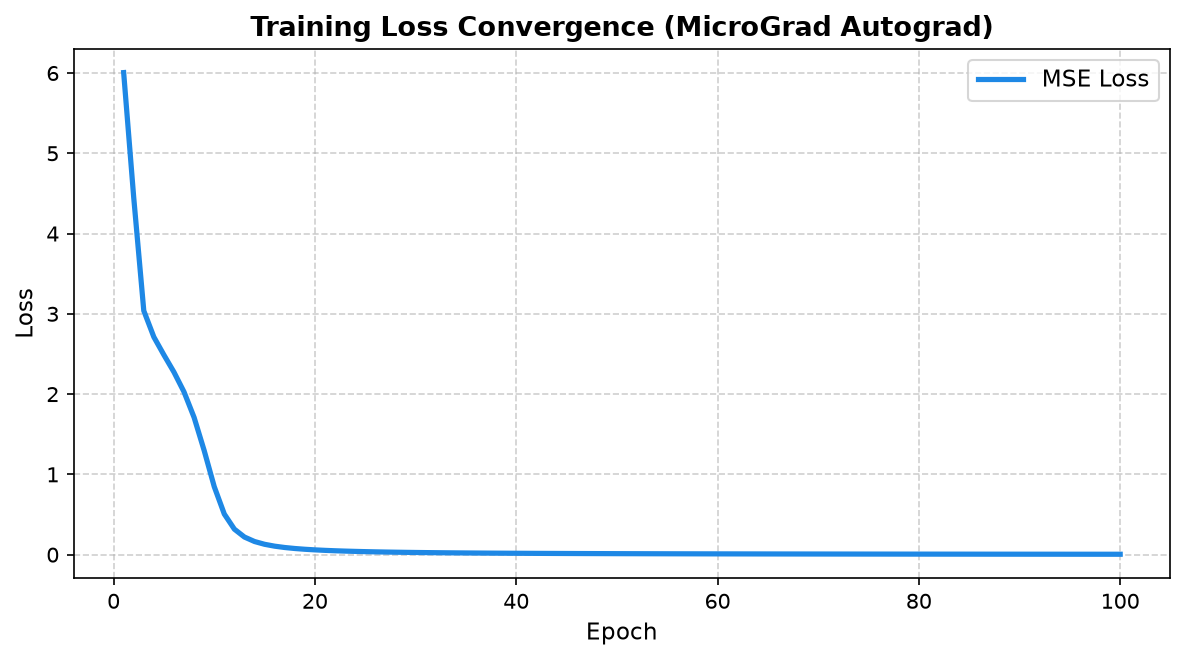

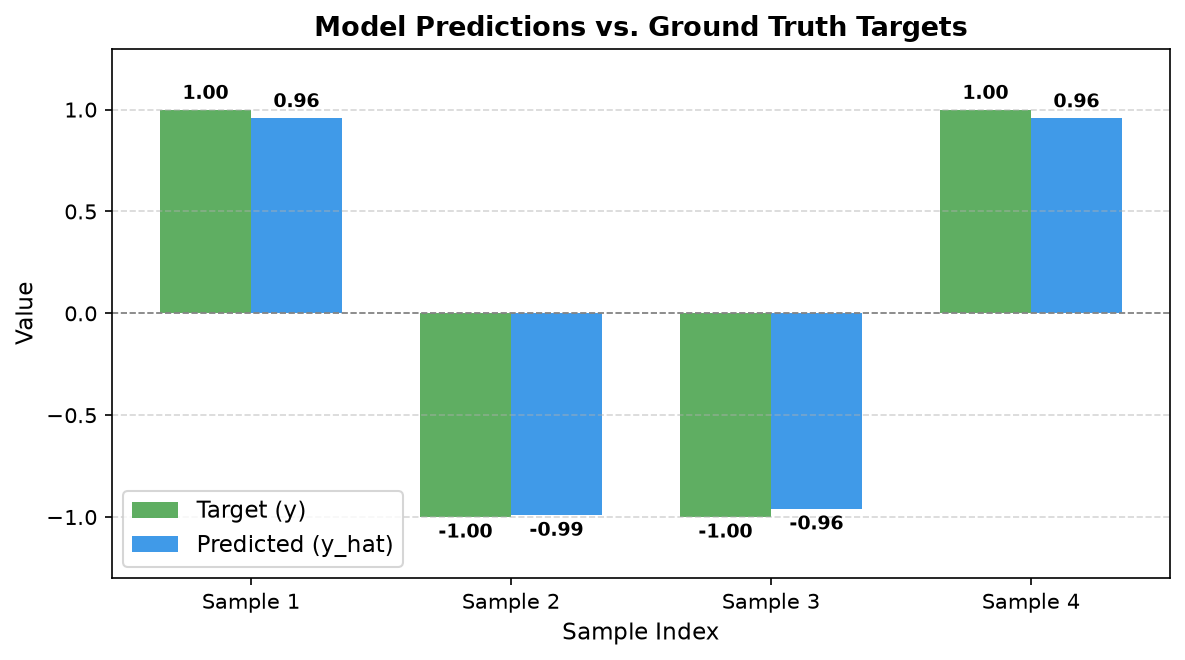

In [9]:
# 1. Loss Curve
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
ax.plot(range(1, epochs + 1), loss_history, color='#1e88e5', lw=2.5, label='MSE Loss')
ax.set_title('Training Loss Convergence (MicroGrad Autograd)', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch', fontsize=11)
ax.set_ylabel('Loss', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(fontsize=11)
plt.tight_layout()
fig.savefig('report/figures/loss_curve.png', bbox_inches='tight')
plt.show()

# 2. Predictions vs Targets
final_preds = [model(x).data for x in xs]

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
indices = range(len(ys))
bar_width = 0.35

rects1 = ax.bar([i - bar_width/2 for i in indices], ys, bar_width, label='Target (y)', color='#43a047', alpha=0.85)
rects2 = ax.bar([i + bar_width/2 for i in indices], final_preds, bar_width, label='Predicted (y_hat)', color='#1e88e5', alpha=0.85)

ax.set_title('Model Predictions vs. Ground Truth Targets', fontsize=13, fontweight='bold')
ax.set_xlabel('Sample Index', fontsize=11)
ax.set_ylabel('Value', fontsize=11)
ax.set_xticks(indices)
ax.set_xticklabels([f"Sample {i+1}" for i in indices])
ax.set_ylim(-1.3, 1.3)
ax.axhline(0, color='gray', lw=0.8, linestyle='--')
ax.grid(True, linestyle='--', alpha=0.5, axis='y')
ax.legend(fontsize=11)

for r in rects1 + rects2:
    h = r.get_height()
    ax.annotate(f"{h:.2f}",
                xy=(r.get_x() + r.get_width() / 2, h),
                xytext=(0, 3 if h >= 0 else -12),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
fig.savefig('report/figures/predictions_comparison.png', bbox_inches='tight')
plt.show()

print("=== Final Evaluation ===")
for i, (target, pred) in enumerate(zip(ys, final_preds)):
    print(f"Sample {i+1}: Target = {target:+.1f} | Prediction = {pred:+.4f} | Error = {abs(target - pred):.4f}")


## 10. 2D Decision Boundary Demonstration

To visually appreciate the representation power of our autograd-trained MLP, we train a 2-input model on a 2D dataset and plot the learned non-linear decision boundary.


2D Decision boundary plotted and saved successfully!


<string>:59: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


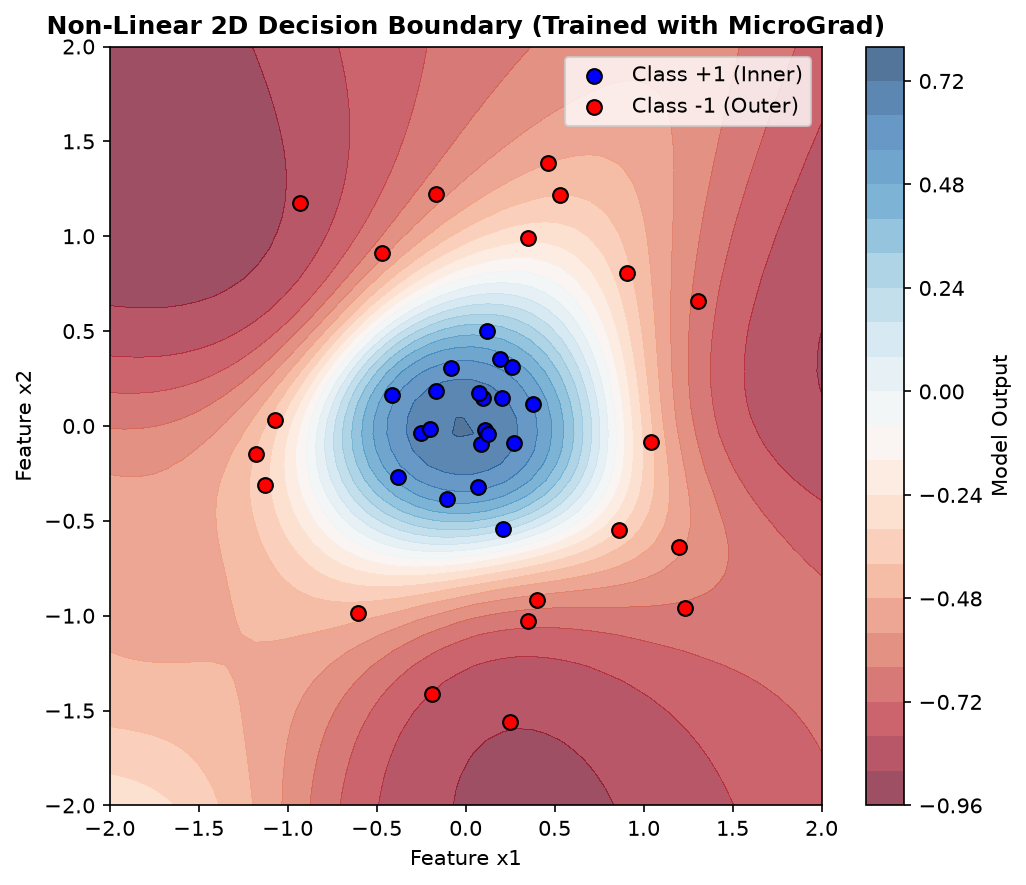

In [10]:
import numpy as np

# Generate 2D dataset: two concentric rings
np.random.seed(42)
num_samples = 40
X_2d = []
y_2d = []

for _ in range(num_samples // 2):
    r = np.random.uniform(0.1, 0.6)
    theta = np.random.uniform(0, 2 * np.pi)
    X_2d.append([r * np.cos(theta), r * np.sin(theta)])
    y_2d.append(1.0)
    
for _ in range(num_samples // 2):
    r = np.random.uniform(1.0, 1.6)
    theta = np.random.uniform(0, 2 * np.pi)
    X_2d.append([r * np.cos(theta), r * np.sin(theta)])
    y_2d.append(-1.0)

# MLP with 2 inputs, two hidden layers of 8 neurons, and 1 output
mlp_2d = MLP(2, [8, 8, 1])
lr_2d = 0.1

for epoch in range(60):
    preds = [mlp_2d(x) for x in X_2d]
    loss = sum((yp - yt)**2 for yp, yt in zip(preds, y_2d)) * (1.0 / len(y_2d))
    mlp_2d.zero_grad()
    loss.backward()
    for p in mlp_2d.parameters():
        p.data -= lr_2d * p.grad

# Plot decision surface
grid_x = np.linspace(-2.0, 2.0, 50)
grid_y = np.linspace(-2.0, 2.0, 50)
GX, GY = np.meshgrid(grid_x, grid_y)
Z = np.zeros_like(GX)

for i in range(GX.shape[0]):
    for j in range(GX.shape[1]):
        Z[i, j] = mlp_2d([GX[i, j], GY[i, j]]).data

fig, ax = plt.subplots(figsize=(7, 6), dpi=150)
cp = ax.contourf(GX, GY, Z, levels=20, cmap='RdBu', alpha=0.7)
plt.colorbar(cp, ax=ax, label='Model Output')

# Plot training points
X_arr = np.array(X_2d)
y_arr = np.array(y_2d)
ax.scatter(X_arr[y_arr == 1.0, 0], X_arr[y_arr == 1.0, 1], c='blue', edgecolors='k', s=50, label='Class +1 (Inner)')
ax.scatter(X_arr[y_arr == -1.0, 0], X_arr[y_arr == -1.0, 1], c='red', edgecolors='k', s=50, label='Class -1 (Outer)')

ax.set_title('Non-Linear 2D Decision Boundary (Trained with MicroGrad)', fontsize=12, fontweight='bold')
ax.set_xlabel('Feature x1')
ax.set_ylabel('Feature x2')
ax.legend(loc='upper right')
plt.tight_layout()
fig.savefig('report/figures/decision_boundary.png', bbox_inches='tight')
plt.show()
print("2D Decision boundary plotted and saved successfully!")


## 11. Conclusion & Key Takeaways

1. **Exact Gradient Flow:** MicroGrad computes exact analytical derivatives for scalar computational graphs via reverse-mode automatic differentiation.
2. **Topological Order:** Backpropagation requires reverse topological sorting to ensure every node's downstream gradients are completely resolved before computing its local derivatives.
3. **Accumulation Property:** Gradient updates must always be accumulated with `+=` to correctly implement the multivariate chain rule across branching DAG paths.
4. **Modularity:** High-level deep learning abstractions (`Neuron`, `Layer`, `MLP`) naturally compose on top of the scalar `Value` engine, enabling training of arbitrary neural network architectures with pure gradient descent.
